
# EXPT NO: 3 — Implementation of Convolutional Neural Networks (CNNs) for Image Classification

**Name:** `Midhun P`  
**Roll No:** `24BAD069`  



In [1]:

# Student details — keep this cell visible for the required screenshot
ROLL_NO = "24BAD069"
NAME = "Midhun P"

print("Student Name:", NAME)
print("Roll No(s):", ROLL_NO)


Student Name: Midhun P
Roll No(s): 24BAD069


## 1. Import Required Libraries

In [2]:

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.20.0


In [3]:

# Set seeds for reproducible results
SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seed:", SEED)


Random seed: 42



# TASK A — DATASET PREPARATION

The experiment requires:
- Downloading/loading an image dataset.
- Preprocessing the images.
- Resizing and normalization where applicable.
- Splitting the data into training, validation, and testing sets.

For this implementation, **CIFAR-10** is used. CIFAR-10 images are already standardized at **32 × 32 × 3**, so no additional resizing is necessary. Pixel values are normalized from `[0, 255]` to `[0, 1]`.


In [4]:

# Load CIFAR-10
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.cifar10.load_data()

# Flatten class labels from shape (n, 1) to (n,)
y_train_full = y_train_full.flatten()
y_test = y_test.flatten()

print("Original training images:", x_train_full.shape)
print("Original training labels:", y_train_full.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2076s 12us/step
Original training images: (50000, 32, 32, 3)
Original training labels: (50000,)
Test images: (10000, 32, 32, 3)
Test labels: (10000,)


In [5]:

# CIFAR-10 class names
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("Number of classes:", len(class_names))
print("Classes:", class_names)


Number of classes: 10
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [6]:

# Normalize image pixels
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Create a validation split from the training data
validation_size = 5000

x_val = x_train_full[-validation_size:]
y_val = y_train_full[-validation_size:]

x_train = x_train_full[:-validation_size]
y_train = y_train_full[:-validation_size]

print("Training set:", x_train.shape, y_train.shape)
print("Validation set:", x_val.shape, y_val.shape)
print("Testing set:", x_test.shape, y_test.shape)


Training set: (45000, 32, 32, 3) (45000,)
Validation set: (5000, 32, 32, 3) (5000,)
Testing set: (10000, 32, 32, 3) (10000,)


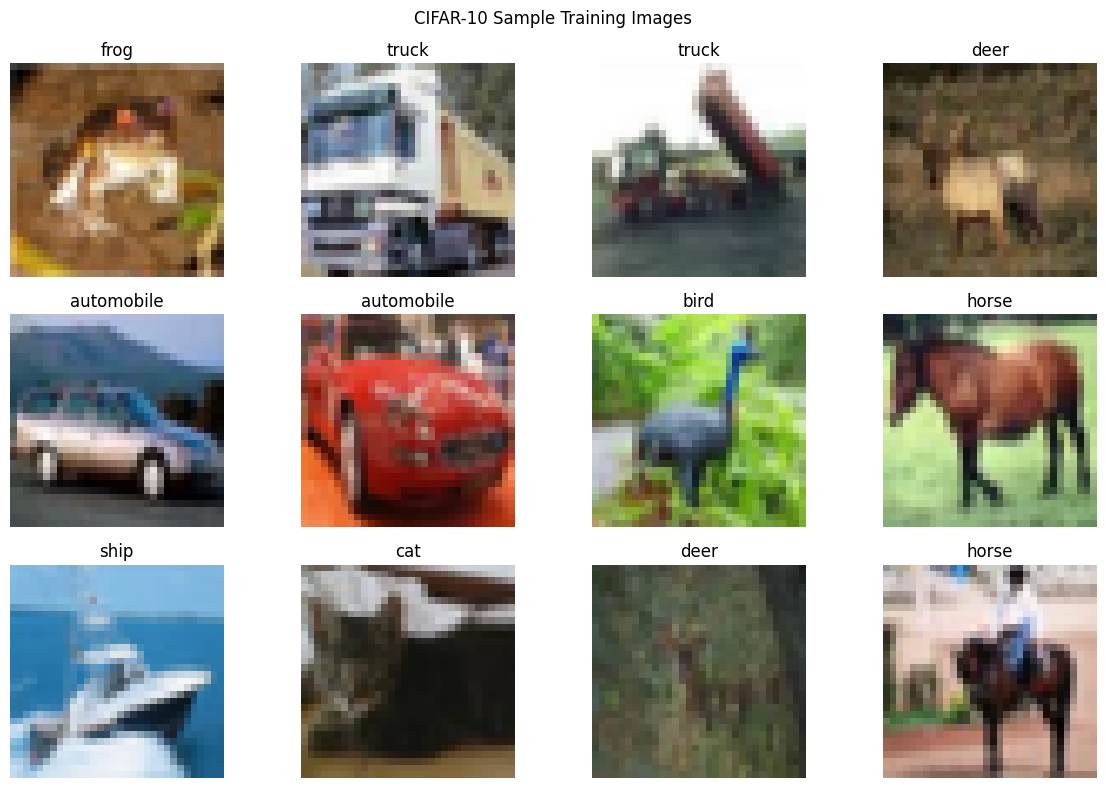

In [7]:

# Display sample images from the training dataset
plt.figure(figsize=(12, 8))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.suptitle("CIFAR-10 Sample Training Images")
plt.tight_layout()
plt.show()


In [8]:

# Check class distribution
class_counts = pd.Series(y_train).value_counts().sort_index()

distribution_df = pd.DataFrame({
    "Class": class_names,
    "Training Images": class_counts.values
})

display(distribution_df)


,Class,Training Images
0,airplane,4507
1,automobile,4512
2,bird,4521
3,cat,4481
4,deer,4525
5,dog,4471
6,frog,4512
7,horse,4515
8,ship,4468
9,truck,4488



# TASK B — CNN MODEL IMPLEMENTATION




In [9]:

# Build the CNN model
model = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545,098 (2.08 MB)

 Trainable params: 545,098 (2.08 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:

# Compile the CNN
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")


Model compiled successfully.



### Compilation Choices

- **Optimizer:** Adam
- **Loss:** Sparse Categorical Crossentropy
- **Metric:** Accuracy

Adam is used as the optimizer for this CNN implementation. Since the CIFAR-10 labels are integer class IDs rather than one-hot encoded vectors, sparse categorical cross-entropy is appropriate.


# TASK C — MODEL TRAINING AND EVALUATION

In [11]:

# Training configuration
EPOCHS = 15
BATCH_SIZE = 64

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)


Epoch 1/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 73s 101ms/step - accuracy: 0.4891 - loss: 1.4243 - val_accuracy: 0.5834 - val_loss: 1.1853
Epoch 2/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 68s 97ms/step - accuracy: 0.6277 - loss: 1.0673 - val_accuracy: 0.6514 - val_loss: 1.0081
Epoch 3/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 68s 97ms/step - accuracy: 0.6797 - loss: 0.9270 - val_accuracy: 0.6840 - val_loss: 0.9321
Epoch 4/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 68s 97ms/step - accuracy: 0.7120 - loss: 0.8316 - val_accuracy: 0.7030 - val_loss: 0.8932
Epoch 5/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 69s 97ms/step - accuracy: 0.7416 - loss: 0.7514 - val_accuracy: 0.7050 - val_loss: 0.8797
Epoch 6/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 82s 97ms/step - accuracy: 0.7657 - loss: 0.6828 - val_accuracy: 0.7028 - val_loss: 0.8938
Epoch 7/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 83s 98ms/step - accuracy: 0.7854 - loss: 0.6210 - val_accuracy: 0.7010 - val_loss: 0.9052
Epoch 8/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 81s 97ms/step - accuracy: 0.8073 - loss: 0.5642 -

In [12]:

# Extract final training and validation metrics
final_train_accuracy = history.history["accuracy"][-1]
final_val_accuracy = history.history["val_accuracy"][-1]
final_train_loss = history.history["loss"][-1]
final_val_loss = history.history["val_loss"][-1]

print(f"Final Training Accuracy:   {final_train_accuracy * 100:.2f}%")
print(f"Final Validation Accuracy: {final_val_accuracy * 100:.2f}%")
print(f"Final Training Loss:       {final_train_loss:.4f}")
print(f"Final Validation Loss:     {final_val_loss:.4f}")


Final Training Accuracy:   90.46%
Final Validation Accuracy: 68.76%
Final Training Loss:       0.2647
Final Validation Loss:     1.3858


In [13]:

# Evaluate on the independent test set
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print(f"Testing Loss:     {test_loss:.4f}")
print(f"Testing Accuracy: {test_accuracy * 100:.2f}%")


Testing Loss:     1.4770
Testing Accuracy: 66.77%


In [14]:

# Create a final results table
final_results = pd.DataFrame({
    "Metric": [
        "Training Accuracy",
        "Validation Accuracy",
        "Training Loss",
        "Validation Loss",
        "Testing Accuracy",
        "Testing Loss"
    ],
    "Value": [
        f"{final_train_accuracy * 100:.2f}%",
        f"{final_val_accuracy * 100:.2f}%",
        f"{final_train_loss:.4f}",
        f"{final_val_loss:.4f}",
        f"{test_accuracy * 100:.2f}%",
        f"{test_loss:.4f}"
    ]
})

display(final_results)


,Metric,Value
0,Training Accuracy,90.46%
1,Validation Accuracy,68.76%
2,Training Loss,0.2647
3,Validation Loss,1.3858
4,Testing Accuracy,66.77%
5,Testing Loss,1.4770


## Accuracy vs Epoch

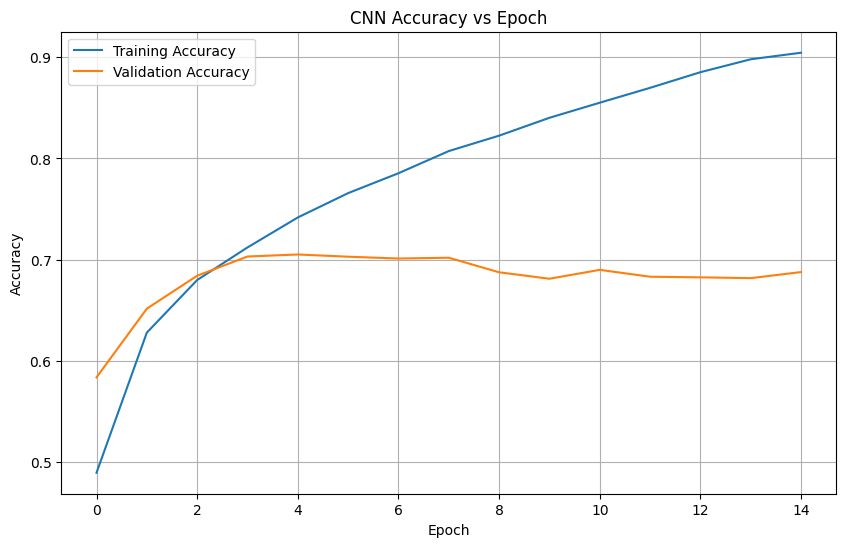

In [15]:

plt.figure(figsize=(10, 6))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("CNN Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


## Loss vs Epoch

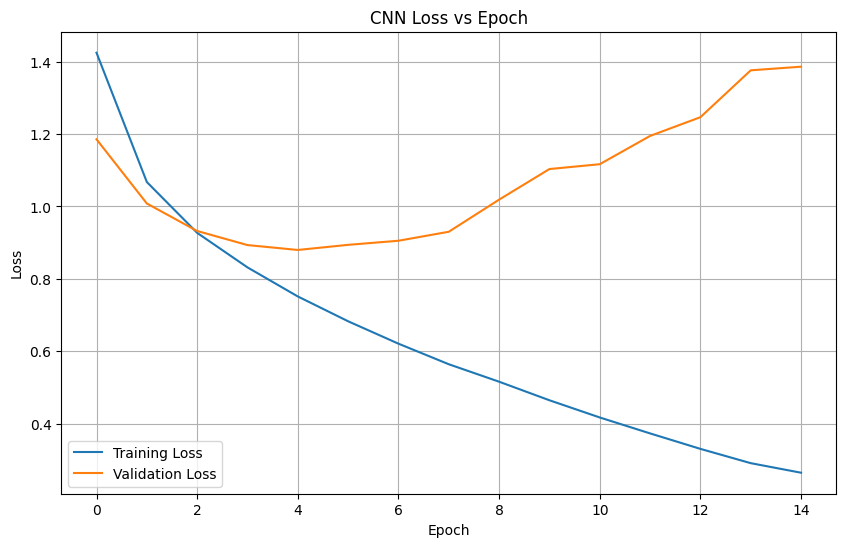

In [16]:

plt.figure(figsize=(10, 6))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("CNN Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()



# TASK D — PERFORMANCE ANALYSIS

The experiment requires analysis of:
- Classification accuracy
- Confusion matrix
- Sample predictions
- Misclassified images


## D1. Classification Accuracy

In [17]:

print("Classification Accuracy Summary")
print("-" * 40)
print(f"Training Accuracy:   {final_train_accuracy * 100:.2f}%")
print(f"Validation Accuracy: {final_val_accuracy * 100:.2f}%")
print(f"Testing Accuracy:    {test_accuracy * 100:.2f}%")


Classification Accuracy Summary
----------------------------------------
Training Accuracy:   90.46%
Validation Accuracy: 68.76%
Testing Accuracy:    66.77%


## D2. Confusion Matrix

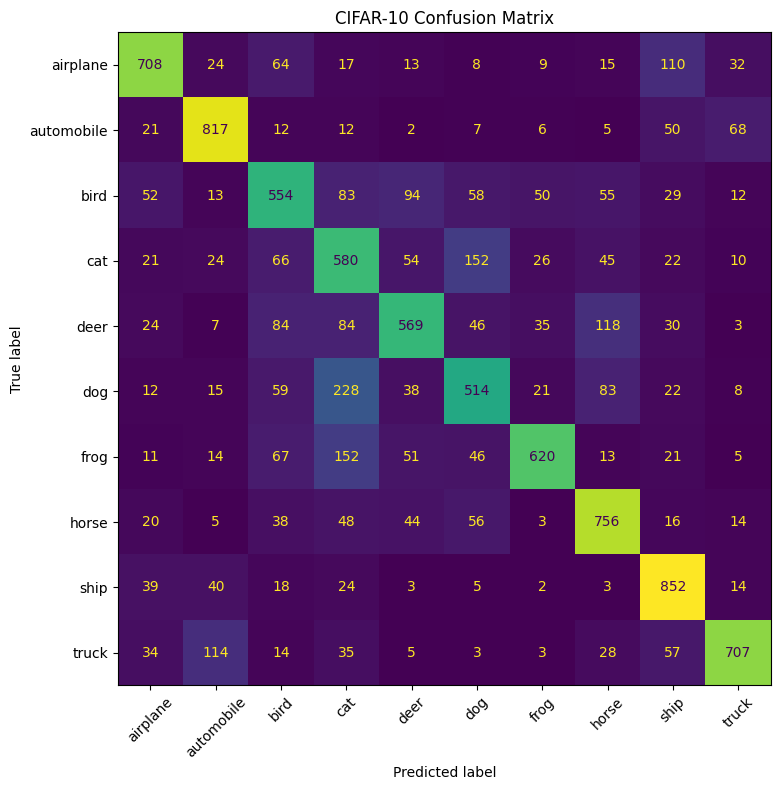

In [18]:

# Generate predictions for the complete test set
y_prob = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=plt.gca(),
    xticks_rotation=45,
    colorbar=False
)

plt.title("CIFAR-10 Confusion Matrix")
plt.tight_layout()
plt.show()


In [19]:

# Classification report
report = classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

display(
    report_df.round(3)
)


,precision,recall,f1-score,support
airplane,0.752,0.708,0.729,1000.000
automobile,0.761,0.817,0.788,1000.000
bird,0.568,0.554,0.561,1000.000
cat,0.459,0.580,0.513,1000.000
deer,0.652,0.569,0.608,1000.000
dog,0.574,0.514,0.542,1000.000
frog,0.800,0.620,0.699,1000.000
horse,0.674,0.756,0.713,1000.000
ship,0.705,0.852,0.771,1000.000
truck,0.810,0.707,0.755,1000.000


## D3. Sample Predictions

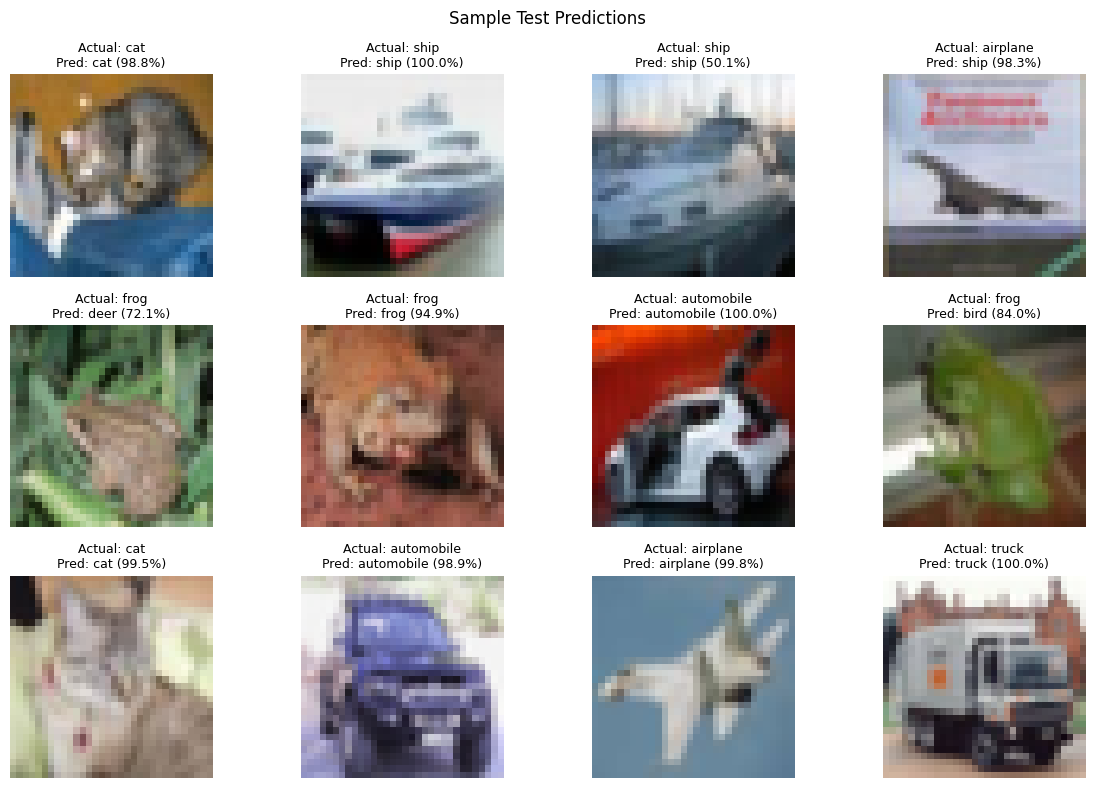

In [20]:

# Display sample predictions
num_samples = 12

plt.figure(figsize=(12, 8))

for i in range(num_samples):
    plt.subplot(3, 4, i + 1)

    plt.imshow(x_test[i])

    actual = class_names[y_test[i]]
    predicted = class_names[y_pred[i]]
    confidence = np.max(y_prob[i]) * 100

    title = (
        f"Actual: {actual}\n"
        f"Pred: {predicted} ({confidence:.1f}%)"
    )

    plt.title(title, fontsize=9)
    plt.axis("off")

plt.suptitle("Sample Test Predictions")
plt.tight_layout()
plt.show()


## D4. Misclassified Images

In [21]:

# Find misclassified images
misclassified_indices = np.where(y_pred != y_test)[0]

print("Total test images:", len(y_test))
print("Correct predictions:", np.sum(y_pred == y_test))
print("Misclassified images:", len(misclassified_indices))
print(
    "Misclassification rate:",
    f"{len(misclassified_indices) / len(y_test) * 100:.2f}%"
)


Total test images: 10000
Correct predictions: 6677
Misclassified images: 3323
Misclassification rate: 33.23%


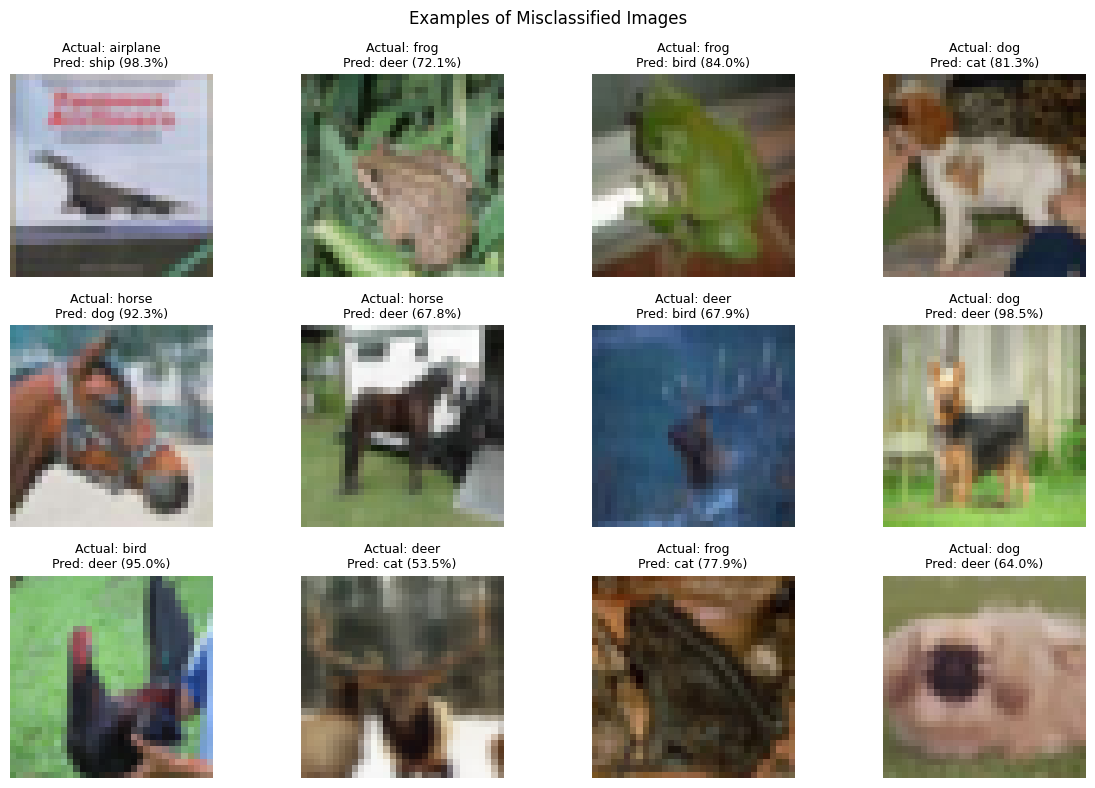

In [22]:

# Display misclassified images
num_misclassified_to_show = min(12, len(misclassified_indices))

plt.figure(figsize=(12, 8))

for i in range(num_misclassified_to_show):
    idx = misclassified_indices[i]

    plt.subplot(3, 4, i + 1)
    plt.imshow(x_test[idx])

    actual = class_names[y_test[idx]]
    predicted = class_names[y_pred[idx]]
    confidence = np.max(y_prob[idx]) * 100

    plt.title(
        f"Actual: {actual}\nPred: {predicted} ({confidence:.1f}%)",
        fontsize=9
    )
    plt.axis("off")

plt.suptitle("Examples of Misclassified Images")
plt.tight_layout()
plt.show()


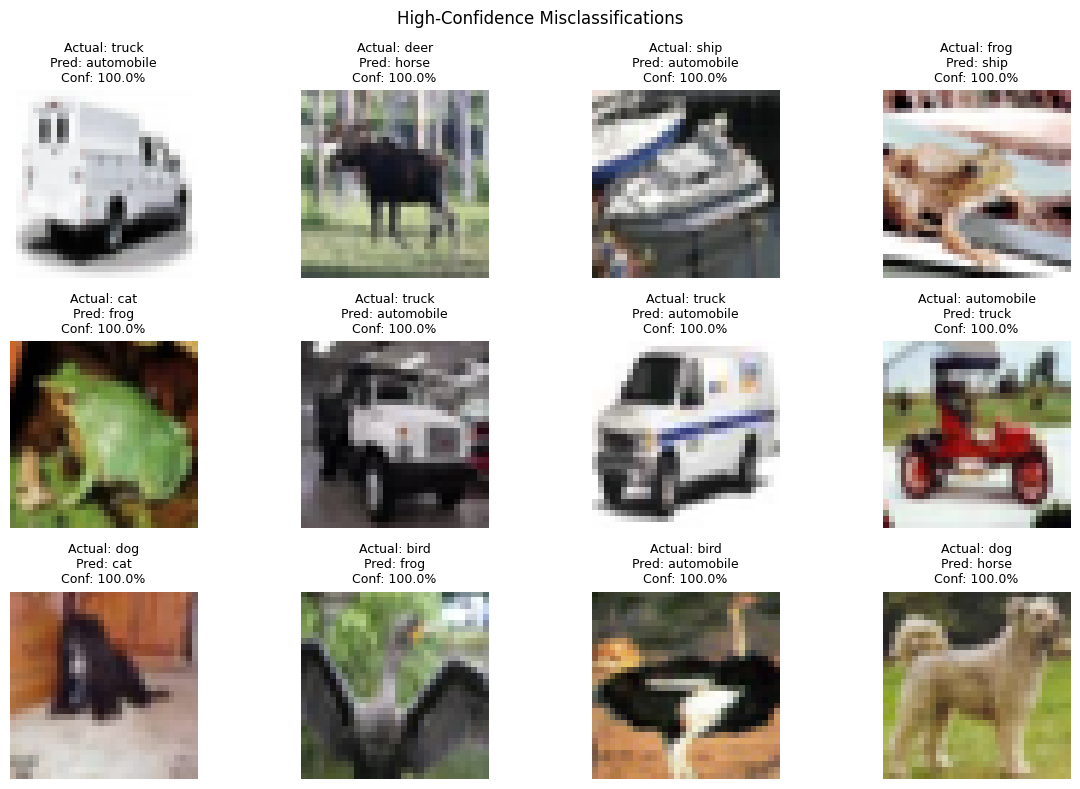

In [23]:

# Show the most confident incorrect predictions
misclassified_confidences = [
    (idx, np.max(y_prob[idx]))
    for idx in misclassified_indices
]

misclassified_confidences.sort(
    key=lambda x: x[1],
    reverse=True
)

top_confident_errors = misclassified_confidences[:12]

plt.figure(figsize=(12, 8))

for i, (idx, confidence) in enumerate(top_confident_errors):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_test[idx])

    actual = class_names[y_test[idx]]
    predicted = class_names[y_pred[idx]]

    plt.title(
        f"Actual: {actual}\nPred: {predicted}\nConf: {confidence * 100:.1f}%",
        fontsize=9
    )
    plt.axis("off")

plt.suptitle("High-Confidence Misclassifications")
plt.tight_layout()
plt.show()



# Save the Trained Model and Results

These cells save the model and experiment tables locally. In Google Colab, you can also copy the files to Google Drive.

Recommended files:
- `cnn_cifar10.keras`
- `cnn_final_results.csv`
- `cnn_classification_report.csv`


In [24]:

# Save model and result tables
MODEL_PATH = "cnn_cifar10.keras"
RESULTS_PATH = "cnn_final_results.csv"
REPORT_PATH = "cnn_classification_report.csv"

model.save(MODEL_PATH)
final_results.to_csv(RESULTS_PATH, index=False)
report_df.to_csv(REPORT_PATH)

print("Saved:")
print(MODEL_PATH)
print(RESULTS_PATH)
print(REPORT_PATH)


Saved:
cnn_cifar10.keras
cnn_final_results.csv
cnn_classification_report.csv



## Optional Google Drive Saving — Google Colab

If you are running this notebook in Google Colab, the following cell can be used to mount Google Drive and copy the model/results into a dedicated experiment folder.


In [25]:

# Google Colab only
try:
    from google.colab import drive
    import shutil

    drive.mount("/content/drive")

    DRIVE_DIR = "/content/drive/MyDrive/EXPT_NO_3_CNN_IMAGE_CLASSIFICATION"
    os.makedirs(DRIVE_DIR, exist_ok=True)

    shutil.copy(MODEL_PATH, DRIVE_DIR)
    shutil.copy(RESULTS_PATH, DRIVE_DIR)
    shutil.copy(REPORT_PATH, DRIVE_DIR)

    print("Files copied to:", DRIVE_DIR)

except ImportError:
    print("Google Colab was not detected. Run this cell in Colab to use Google Drive.")
except Exception as e:
    print("Google Drive saving could not be completed:", e)


Mounted at /content/drive
Files copied to: /content/drive/MyDrive/EXPT_NO_3_CNN_IMAGE_CLASSIFICATION
